# Modeling experiments

Builds on `modeling_baselines.ipynb` with three stronger model families, each chosen for a specific reason:

| Model | Defensible reason |
|---|---|
| **Elastic-net logistic regression** | Sleep features are strongly correlated; L1/L2 shrinkage stabilizes coefficients while staying interpretable for the research question. |
| **Random forest** | Captures non-linear effects and interactions (e.g. short sleep mattering more after an inactive day) with little tuning. |
| **LightGBM** | Strongest expected performer; handles missing sleep/activity natively (≈20–55% missing on some features); pairs with SHAP. |

Not pursued: SVC (no native missing handling or interpretability; nothing it adds over the above), MLP (≈4k labelled rows from 49 people does not justify the complexity), XGBoost/CatBoost (redundant with LightGBM).

**Evaluation.** Same participant-grouped outer folds as the baselines. Hyperparameters are tuned with **nested CV**: a `RandomizedSearchCV` with an inner `StratifiedGroupKFold` runs on the outer-training people only (see `src/models/tune.py`), so the reported scores are not inflated by tuning on the people being scored.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# ---- project paths (works when the notebook runs from notebooks/ or the repo root) ----
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRAIN_PATH = ROOT / "data" / "processed" / "df_train_20261028.csv"
RESULTS = ROOT / "results"
(RESULTS / "interpretability").mkdir(parents=True, exist_ok=True)

# make ROOT/src importable, and fail early with a clear message if files are missing
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
needed = ["src/__init__.py", "src/models/__init__.py", "src/models/data.py",
          "src/models/train.py", "src/models/tune.py"]
missing = [f for f in needed if not (ROOT / f).exists()]
assert not missing, f"Missing in {ROOT}: {missing}"
assert TRAIN_PATH.exists(), f"Training file not found: {TRAIN_PATH}"
warnings.filterwarnings("ignore", category=UserWarning)

from src.models.data import load_xy, FEATURES, SLEEP_FEATURES, ACTIVITY_FEATURES
from src.models import train as T
from src.models import tune as TU
pd.set_option("display.width", 160)
print("ROOT:", ROOT)
N_ITER = 20  # random-search candidates per outer fold; raise for a final run

ROOT: /Users/linhpham/Documents/GitHub/fall-2026-bad-mood-prediction


In [2]:
X, y, groups, table = load_xy(TRAIN_PATH)
folds = T.fixed_folds(X, y, groups)   # identical to the baselines notebook (same seed)
print(f"{len(X):,} reports | {groups.nunique()} participants")

3,937 reports | 49 participants


## 1. Nested-CV runs
Each takes a minute or two; LightGBM is the slowest.

In [3]:
experiments = {
    "Elastic-net LR": (T.make_logistic(C=0.1, l1_ratio=0.5), TU.SEARCH_SPACES["elasticnet_lr"]),
    "Random forest":  (T.make_random_forest(),                TU.SEARCH_SPACES["random_forest"]),
    "LightGBM":       (T.make_lightgbm(),                     TU.SEARCH_SPACES["lightgbm"]),
}
exp_folds, exp_oof = [], []
for name, (model, space) in experiments.items():
    f, o = TU.nested_cv(model, space, X, y, groups, folds, name, n_iter=N_ITER)
    exp_folds.append(f); exp_oof.append(o)
    print(f"{name:16s} outer AUC = {f.roc_auc.mean():.3f} ± {f.roc_auc.std():.3f}")
exp_folds = pd.concat(exp_folds, ignore_index=True); exp_oof = pd.concat(exp_oof, ignore_index=True)

Elastic-net LR   outer AUC = 0.469 ± 0.071


/Users/linhpham/miniconda3/envs/erdos_ds_environment/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/linhpham/miniconda3/envs/erdos_ds_environment/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/linhpham/miniconda3/envs/erdos_ds_environment/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.


Random forest    outer AUC = 0.493 ± 0.063
LightGBM         outer AUC = 0.529 ± 0.054


## 2. Compare against baselines (same folds)

In [4]:
base_folds = pd.read_csv(RESULTS / "baselines_fold_scores.csv")
keep = ["Dummy (stratified)", "Logistic (L2)", "Decision tree (d=3)"]
all_folds = pd.concat([base_folds[base_folds.model.isin(keep)], exp_folds.drop(columns=["best_params", "inner_best_auc"])],
                      ignore_index=True)
T.summarize(all_folds)

,accuracy,no_info_acc,hit_rate,false_alarm,roc_auc,pr_auc,balanced_acc,precision_bad,f1_bad,brier
model,,,,,,,,,,
LightGBM,0.507 ± 0.026,0.635 ± 0.022,0.564 ± 0.137,0.526 ± 0.104,0.529 ± 0.054,0.397 ± 0.051,0.519 ± 0.03,0.38 ± 0.039,0.449 ± 0.061,0.268 ± 0.012
Dummy (stratified),0.542 ± 0.025,0.635 ± 0.022,0.362 ± 0.033,0.354 ± 0.019,0.504 ± 0.024,0.367 ± 0.021,0.504 ± 0.024,0.37 ± 0.033,0.365 ± 0.03,0.458 ± 0.025
Random forest,0.47 ± 0.056,0.635 ± 0.022,0.565 ± 0.145,0.582 ± 0.111,0.493 ± 0.063,0.378 ± 0.05,0.492 ± 0.056,0.357 ± 0.065,0.433 ± 0.076,0.26 ± 0.009
Logistic (L2),0.474 ± 0.069,0.635 ± 0.022,0.552 ± 0.146,0.568 ± 0.191,0.487 ± 0.057,0.367 ± 0.036,0.492 ± 0.037,0.364 ± 0.043,0.428 ± 0.04,0.275 ± 0.024
Decision tree (d=3),0.459 ± 0.096,0.635 ± 0.022,0.445 ± 0.282,0.526 ± 0.283,0.473 ± 0.045,0.361 ± 0.038,0.46 ± 0.052,0.325 ± 0.05,0.351 ± 0.088,0.275 ± 0.016
Elastic-net LR,0.426 ± 0.093,0.635 ± 0.022,0.639 ± 0.25,0.689 ± 0.259,0.469 ± 0.071,0.351 ± 0.044,0.475 ± 0.061,0.352 ± 0.061,0.436 ± 0.071,0.266 ± 0.021


**Reading accuracy (primary KPI in `kpis.md`).** Bad mood is only ~37% of reports, so always predicting "not bad" already scores ~63% accuracy (`no_info_acc`). Accuracy is only meaningful relative to that number. `hit_rate` (share of bad moods caught) and `false_alarm` (share of non-bad reports flagged as bad) show the trade-off behind it; a model with hit rate ≈ false-alarm rate is not discriminating. All 0/1 metrics use a 0.5 probability threshold. Rows are ordered by ROC-AUC, which summarizes the hit vs. false-alarm trade-off across all thresholds.

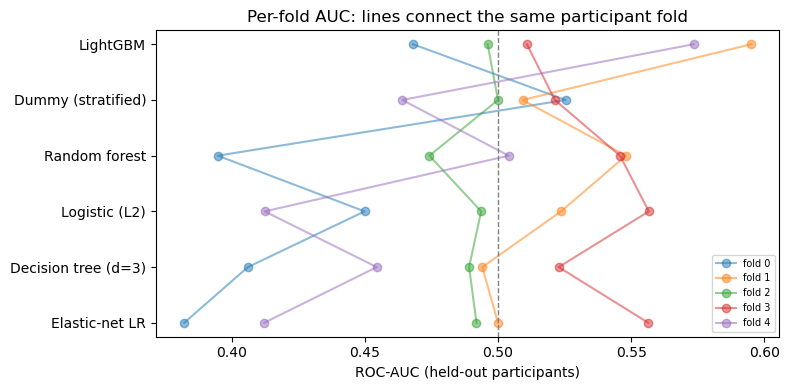

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
models = list(all_folds.groupby("model", sort=False)["roc_auc"].mean().sort_values().index)
for k in sorted(all_folds.fold.unique()):
    v = all_folds[all_folds.fold == k].set_index("model").loc[models, "roc_auc"]
    ax.plot(v.values, range(len(models)), marker="o", alpha=.5, label=f"fold {k}")
ax.axvline(.5, ls="--", c="grey", lw=1); ax.set_yticks(range(len(models)), models)
ax.set_xlabel("ROC-AUC (held-out participants)"); ax.legend(fontsize=7, loc="lower right")
ax.set_title("Per-fold AUC: lines connect the same participant fold")
plt.tight_layout(); plt.savefig(RESULTS / "experiments_auc_by_fold.png", dpi=150); plt.show()

Lines that move together mean some participant folds are simply harder than others; crossing lines mean the ranking of models is unstable.

In [6]:
# Paired comparison vs. the L2 logistic baseline (same folds -> fold-wise differences)
piv = all_folds.pivot(index="fold", columns="model", values="roc_auc")
diff = piv.sub(piv["Logistic (L2)"], axis=0).drop(columns="Logistic (L2)")
pd.DataFrame({"mean ΔAUC vs L2 logistic": diff.mean().round(3), "folds better": (diff > 0).sum(),
              "min Δ": diff.min().round(3), "max Δ": diff.max().round(3)}).sort_values("mean ΔAUC vs L2 logistic")

,mean ΔAUC vs L2 logistic,folds better,min Δ,max Δ
model,,,,
Elastic-net LR,-0.019,0,-0.068,-0.000
Decision tree (d=3),-0.014,1,-0.044,0.042
Random forest,0.006,2,-0.055,0.092
Dummy (stratified),0.017,3,-0.035,0.075
LightGBM,0.041,4,-0.046,0.161


In [7]:
# Hyperparameters chosen in each outer fold (stability check)
exp_folds[["model", "fold", "inner_best_auc", "roc_auc", "best_params"]]

,model,fold,inner_best_auc,roc_auc,best_params
0,Elastic-net LR,0,0.562,0.382187,"{'C': 0.0063, 'l1_ratio': 0.5142}"
1,Elastic-net LR,1,0.500,0.500000,"{'C': 0.0017, 'l1_ratio': 0.8662}"
2,Elastic-net LR,2,0.527,0.491908,"{'C': 0.8472, 'l1_ratio': 0.5987}"
3,Elastic-net LR,3,0.525,0.556387,"{'C': 0.2693, 'l1_ratio': 0.1705}"
4,Elastic-net LR,4,0.546,0.412207,"{'C': 0.0667, 'l1_ratio': 0.7852}"
5,Random forest,0,0.547,0.394784,"{'max_depth': 5, 'max_features': 'sqrt', 'min_..."
6,Random forest,1,0.538,0.548034,"{'max_depth': 5, 'max_features': 0.5, 'min_sam..."
7,Random forest,2,0.494,0.474247,"{'max_depth': 8, 'max_features': 'sqrt', 'min_..."
8,Random forest,3,0.507,0.545799,"{'max_depth': 8, 'max_features': 0.3, 'min_sam..."
9,Random forest,4,0.524,0.503981,"{'max_depth': 5, 'max_features': 0.5, 'min_sam..."


## 3. Error analysis — do errors cluster?
Out-of-fold predictions let us check every participant as an 'unseen' person.

In [8]:
best_name = exp_folds.groupby("model")["roc_auc"].mean().idxmax()
o = exp_oof[exp_oof.model == best_name].reset_index(drop=True)  # row i = table row i
o = o.join(table[["hour", "age_30plus", "male"]])
print("Best experimental model by mean outer AUC:", best_name)

from sklearn.metrics import roc_auc_score
def grp_auc(d):
    return pd.Series({"n": len(d), "bad_rate": d.y.mean(),
                      "auc": roc_auc_score(d.y, d.proba) if d.y.nunique() == 2 else np.nan})
o["time_of_day"] = pd.cut(o.hour, [-1, 11, 16, 24], labels=["morning (<12)", "afternoon (12-16)", "evening (17+)"])
o["age_group"] = o.age_30plus.map({1: ">=30", 0: "<30"}); o["gender"] = o.male.map({1: "male", 0: "female"})
display(pd.concat({c: o.groupby(c, observed=True).apply(grp_auc) for c in ["time_of_day", "age_group", "gender"]}).round(3))

Best experimental model by mean outer AUC: LightGBM


n  bad_rate    auc
time_of_day morning (<12)       876.0     0.312  0.574
            afternoon (12-16)  1337.0     0.371  0.519
            evening (17+)      1724.0     0.389  0.491
age_group   <30                1463.0     0.367  0.521
            >=30               2445.0     0.365  0.526
gender      female             1317.0     0.399  0.501
            male               2597.0     0.349  0.543

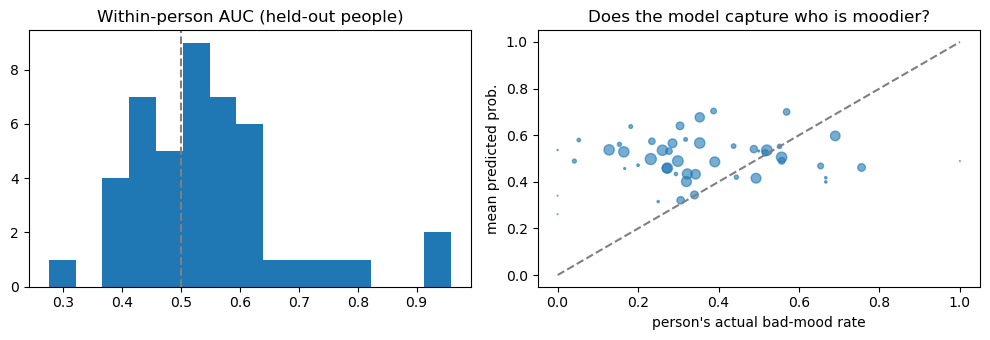

Median within-person AUC: 0.526  |  corr(actual rate, mean prediction): 0.100


In [9]:
# Per-person: how well does the model rank reports *within* each unseen person?
pp = o.groupby("id").apply(grp_auc).dropna(subset=["auc"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(pp.auc, bins=15); ax[0].axvline(.5, ls="--", c="grey"); ax[0].set_title("Within-person AUC (held-out people)")
mean_p = o.groupby("id").agg(bad_rate=("y", "mean"), mean_pred=("proba", "mean"), n=("y", "size"))
ax[1].scatter(mean_p.bad_rate, mean_p.mean_pred, s=mean_p.n / 3, alpha=.6)
ax[1].plot([0, 1], [0, 1], ls="--", c="grey"); ax[1].set_xlabel("person's actual bad-mood rate"); ax[1].set_ylabel("mean predicted prob.")
ax[1].set_title("Does the model capture who is moodier?")
plt.tight_layout(); plt.savefig(RESULTS / "experiments_person_level_errors.png", dpi=150); plt.show()
print(f"Median within-person AUC: {pp.auc.median():.3f}  |  corr(actual rate, mean prediction): "
      f"{mean_p.bad_rate.corr(mean_p.mean_pred):.3f}")

If within-person AUC hovers near 0.5 while the person-level correlation is positive, the model mostly learns *who* is generally moodier (between-person differences) rather than *when* a given person will be in a bad mood. That's a key interpretive point for the write-up and a pointer back to feature engineering (e.g. person-centered features such as sleep relative to one's own average).

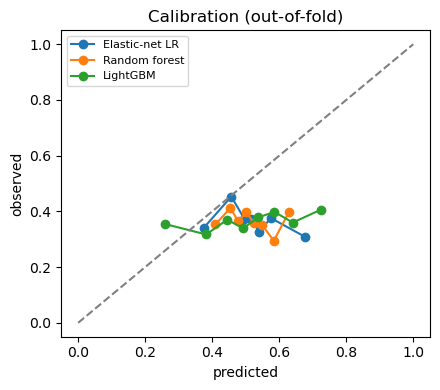

In [10]:
# Calibration of the out-of-fold probabilities
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(4.5, 4))
for m in experiments:
    d = exp_oof[exp_oof.model == m]
    pt, pp_ = calibration_curve(d.y, d.proba, n_bins=8, strategy="quantile")
    ax.plot(pp_, pt, marker="o", label=m)
ax.plot([0, 1], [0, 1], ls="--", c="grey"); ax.set_xlabel("predicted"); ax.set_ylabel("observed"); ax.legend(fontsize=8)
ax.set_title("Calibration (out-of-fold)"); plt.tight_layout(); plt.savefig(RESULTS / "experiments_calibration.png", dpi=150); plt.show()

Probabilities are pulled toward 0.5 because of `class_weight='balanced'`; that affects calibration/Brier but not ranking (AUC). Recalibrate the final model if calibrated probabilities matter for your KPIs.

## 4. Interpretability

In [11]:
# Elastic-net coefficients (refit on all training people with params tuned on all training people)
en_search = TU.tune_final(T.make_logistic(C=0.1, l1_ratio=0.5), TU.SEARCH_SPACES["elasticnet_lr"], X, y, groups, n_iter=N_ITER)
en = en_search.best_estimator_
names = en.named_steps["impute"].get_feature_names_out(FEATURES)
en_coef = pd.Series(en.named_steps["model"].coef_[0], index=names).sort_values(key=abs, ascending=False)
en_coef.to_csv(RESULTS / "interpretability" / "elasticnet_coefficients.csv")
print("Tuned params:", en_search.best_params_, "| features zeroed out:", int((en_coef == 0).sum()), "of", len(en_coef))
if (en_coef != 0).sum() == 0:
    # Tuning picked an intercept-only model: the penalty found no reliable signal.
    # For a descriptive look at direction/size only, refit at a moderate fixed penalty.
    print("Tuned model is intercept-only -> showing a descriptive fit at C=0.1, l1_ratio=0.5 (not a tuned model).")
    en_desc = T.make_logistic(C=0.1, l1_ratio=0.5).fit(X, y)
    en_coef = pd.Series(en_desc.named_steps["model"].coef_[0], index=names).sort_values(key=abs, ascending=False)
    en_coef.to_csv(RESULTS / "interpretability" / "elasticnet_coefficients_descriptive_C0.1.csv")
en_coef[en_coef != 0].round(3).rename("standardized coef").to_frame()

Tuned params: {'model__C': np.float64(0.0017073967431528124), 'model__l1_ratio': np.float64(0.8661761457749352)} | features zeroed out: 49 of 49
Tuned model is intercept-only -> showing a descriptive fit at C=0.1, l1_ratio=0.5 (not a tuned model).


,standardized coef
male,-0.210
bmi_num,0.165
hour,0.132
missingindicator_daily_exertion_points_percentage_lag1,-0.127
daily_resting_hr_lag1,-0.123
missingindicator_daily_sleep_points_percentage,-0.121
daily_sleep_deep_ratio,-0.114
daily_nremhr,0.112
daily_lightly_active_minutes_lag1,0.106
daily_sedentary_minutes_lag1,0.100


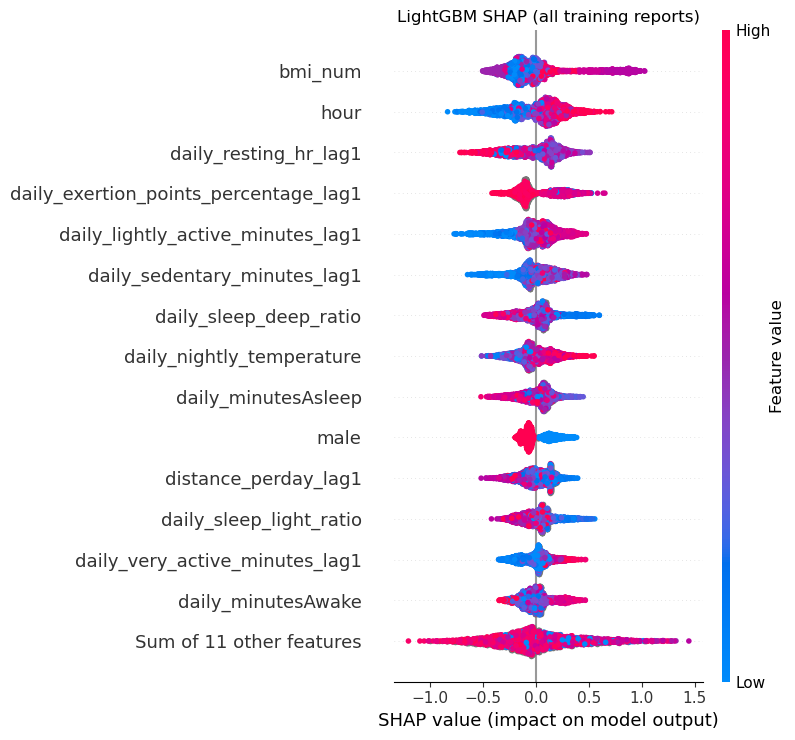

In [12]:
# SHAP for LightGBM (refit with params tuned on all training people)
import shap
lgb_search = TU.tune_final(T.make_lightgbm(), TU.SEARCH_SPACES["lightgbm"], X, y, groups, n_iter=N_ITER)
lgb = lgb_search.best_estimator_.named_steps["model"]
explainer = shap.TreeExplainer(lgb)
sv = explainer(X)
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("LightGBM SHAP (all training reports)"); plt.tight_layout()
plt.savefig(RESULTS / "interpretability" / "lightgbm_shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()
pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False).to_csv(
    RESULTS / "interpretability" / "lightgbm_mean_abs_shap.csv")

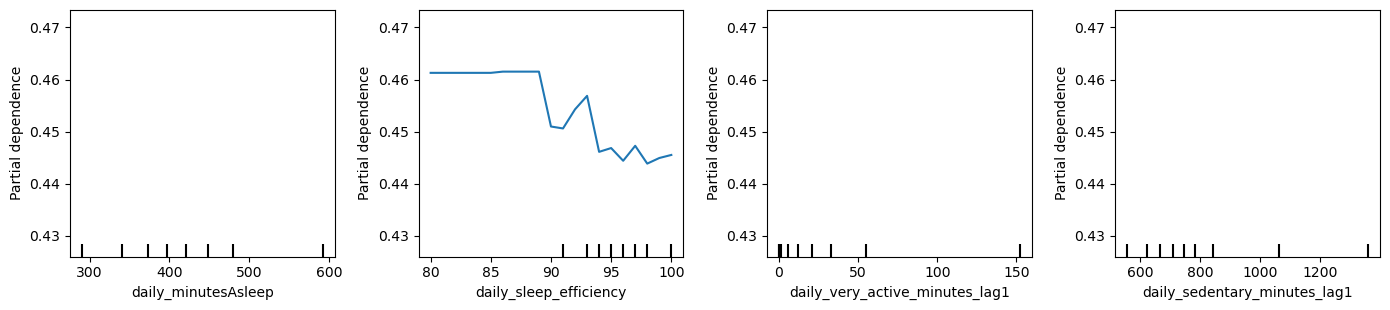

In [13]:
# Partial dependence for the main sleep and activity features
from sklearn.inspection import PartialDependenceDisplay
pd_feats = ["daily_minutesAsleep", "daily_sleep_efficiency", "daily_very_active_minutes_lag1", "daily_sedentary_minutes_lag1"]
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
PartialDependenceDisplay.from_estimator(lgb_search.best_estimator_, X, pd_feats, ax=ax, kind="average")
plt.tight_layout(); plt.savefig(RESULTS / "interpretability" / "lightgbm_partial_dependence.png", dpi=150); plt.show()

## 5. Ablation: is there signal beyond time of day and demographics?
The research question is about sleep and exercise. If `hour` and person-level variables carry most of the signal, that needs to be reported.

In [14]:
from src.models.data import PERSON_FEATURES, CONTEXT_FEATURES
feature_sets = {
    "context + person only": CONTEXT_FEATURES + PERSON_FEATURES,
    "sleep + activity only": SLEEP_FEATURES + ACTIVITY_FEATURES,
    "all features":          FEATURES,
}
abl = []
for fs_name, cols in feature_sets.items():
    for m_name, model in [("Logistic (L2)", T.make_logistic()), ("LightGBM", T.make_lightgbm())]:
        f, _ = T.evaluate_cv(model, X[cols], y, groups, folds, f"{m_name} | {fs_name}")
        abl.append(f)
abl = pd.concat(abl, ignore_index=True)
abl.to_csv(RESULTS / "experiments_ablation_fold_scores.csv", index=False)
T.summarize(abl)[["accuracy", "hit_rate", "false_alarm", "roc_auc", "pr_auc", "balanced_acc"]]

,accuracy,hit_rate,false_alarm,roc_auc,pr_auc,balanced_acc
model,,,,,,
LightGBM | context + person only,0.54 ± 0.077,0.555 ± 0.137,0.469 ± 0.176,0.556 ± 0.067,0.418 ± 0.064,0.543 ± 0.049
LightGBM | all features,0.522 ± 0.044,0.532 ± 0.086,0.484 ± 0.081,0.532 ± 0.059,0.398 ± 0.056,0.524 ± 0.04
Logistic (L2) | context + person only,0.511 ± 0.041,0.504 ± 0.155,0.489 ± 0.134,0.532 ± 0.046,0.392 ± 0.03,0.508 ± 0.032
LightGBM | sleep + activity only,0.497 ± 0.032,0.51 ± 0.129,0.509 ± 0.113,0.499 ± 0.037,0.381 ± 0.049,0.5 ± 0.024
Logistic (L2) | all features,0.474 ± 0.069,0.552 ± 0.146,0.568 ± 0.191,0.487 ± 0.057,0.367 ± 0.036,0.492 ± 0.037
Logistic (L2) | sleep + activity only,0.441 ± 0.077,0.543 ± 0.23,0.613 ± 0.246,0.454 ± 0.056,0.342 ± 0.031,0.465 ± 0.045


Ablation uses default (untuned) hyperparameters so it is a quick, like-for-like comparison of feature sets.

## 6. Iteration 2: person-centered features
Feedback loop from the error analysis: if raw values mostly encode *who* someone is, express each night relative to that person's own average (`<feature>_pc`). The average is computed from the person's Fitbit data only (no mood labels), so it is available for a new person once they've worn the device for a while. Same folds, default hyperparameters.

In [15]:
from src.models.data import PC_FEATURES
X_pc, y_pc, g_pc, _ = load_xy(TRAIN_PATH, person_centered=True)
assert (y_pc.values == y.values).all() and (g_pc.values == groups.values).all()  # same rows -> same folds valid
pc_sets = {"raw features": FEATURES, "person-centered only": PC_FEATURES + CONTEXT_FEATURES + PERSON_FEATURES,
           "raw + person-centered": FEATURES + PC_FEATURES}
it2 = []
for fs_name, cols in pc_sets.items():
    for m_name, model in [("Logistic (L2)", T.make_logistic()), ("Elastic-net LR", T.make_logistic(C=0.1, l1_ratio=0.5)),
                          ("LightGBM", T.make_lightgbm())]:
        f, _ = T.evaluate_cv(model, X_pc[cols], y, groups, folds, f"{m_name} | {fs_name}")
        it2.append(f)
it2 = pd.concat(it2, ignore_index=True)
it2.to_csv(RESULTS / "experiments_iteration2_fold_scores.csv", index=False)
T.summarize(it2)[["accuracy", "hit_rate", "false_alarm", "roc_auc", "pr_auc", "balanced_acc"]]

,accuracy,hit_rate,false_alarm,roc_auc,pr_auc,balanced_acc
model,,,,,,
LightGBM | person-centered only,0.546 ± 0.027,0.446 ± 0.062,0.396 ± 0.055,0.543 ± 0.028,0.405 ± 0.043,0.525 ± 0.027
LightGBM | raw features,0.522 ± 0.044,0.532 ± 0.086,0.484 ± 0.081,0.532 ± 0.059,0.398 ± 0.056,0.524 ± 0.04
LightGBM | raw + person-centered,0.521 ± 0.051,0.482 ± 0.061,0.456 ± 0.078,0.53 ± 0.052,0.396 ± 0.057,0.513 ± 0.047
Logistic (L2) | person-centered only,0.515 ± 0.056,0.525 ± 0.115,0.49 ± 0.116,0.518 ± 0.064,0.394 ± 0.059,0.518 ± 0.045
Elastic-net LR | person-centered only,0.511 ± 0.055,0.504 ± 0.115,0.482 ± 0.111,0.512 ± 0.067,0.389 ± 0.062,0.511 ± 0.046
Logistic (L2) | raw features,0.474 ± 0.069,0.552 ± 0.146,0.568 ± 0.191,0.487 ± 0.057,0.367 ± 0.036,0.492 ± 0.037
Elastic-net LR | raw features,0.473 ± 0.072,0.541 ± 0.145,0.564 ± 0.195,0.486 ± 0.057,0.365 ± 0.04,0.488 ± 0.041
Elastic-net LR | raw + person-centered,0.468 ± 0.084,0.505 ± 0.137,0.552 ± 0.213,0.476 ± 0.07,0.36 ± 0.048,0.477 ± 0.049
Logistic (L2) | raw + person-centered,0.479 ± 0.09,0.491 ± 0.088,0.525 ± 0.189,0.473 ± 0.083,0.361 ± 0.075,0.483 ± 0.061


## 7. Save to the comparison table

In [16]:
s = exp_folds.drop(columns=["fold", "best_params"]).groupby("model", sort=False).agg(["mean", "std"])
s.columns = [f"{a}_{b}" for a, b in s.columns]; s = s.reset_index()
s.insert(1, "family", ["linear (regularized)", "tree ensemble", "gradient boosting"])
s.insert(2, "hyperparameters", [f"nested random search, n_iter={N_ITER}; per-fold choices in experiments_fold_scores.csv"] * 3)
s.insert(3, "notebook", "modeling_experiments")
s2 = it2.drop(columns=["fold"]).groupby("model", sort=False).agg(["mean", "std"])
s2.columns = [f"{a}_{b}" for a, b in s2.columns]; s2 = s2.reset_index()
s2.insert(1, "family", s2.model.str.split(" \\| ").str[0].map(
    {"Logistic (L2)": "linear", "Elastic-net LR": "linear (regularized)", "LightGBM": "gradient boosting"}))
s2.insert(2, "hyperparameters", "defaults (untuned); iteration 2 feature sets")
s2.insert(3, "notebook", "modeling_experiments")
comp = pd.read_csv(RESULTS / "model_comparison.csv")
comp = pd.concat([comp[comp.notebook != "modeling_experiments"], s, s2], ignore_index=True)
comp.to_csv(RESULTS / "model_comparison.csv", index=False)
exp_folds.to_csv(RESULTS / "experiments_fold_scores.csv", index=False)
exp_oof.to_csv(RESULTS / "experiments_oof_predictions.csv", index=False)
comp[["model", "family", "accuracy_mean", "no_info_acc_mean", "hit_rate_mean", "false_alarm_mean", "roc_auc_mean", "roc_auc_std", "pr_auc_mean", "balanced_acc_mean", "brier_mean"]].round(3)

,model,family,accuracy_mean,no_info_acc_mean,hit_rate_mean,false_alarm_mean,roc_auc_mean,roc_auc_std,pr_auc_mean,balanced_acc_mean,brier_mean
0,Dummy (most frequent),dummy,0.635,0.635,0.000,0.000,0.500,0.000,0.365,0.500,0.365
1,Dummy (stratified),dummy,0.542,0.635,0.362,0.354,0.504,0.024,0.367,0.504,0.458
2,Logistic (L2),linear,0.474,0.635,0.552,0.568,0.487,0.057,0.367,0.492,0.275
3,Decision tree (d=3),tree,0.459,0.635,0.445,0.526,0.473,0.045,0.361,0.460,0.275
4,Elastic-net LR,linear (regularized),0.426,0.635,0.639,0.689,0.469,0.071,0.351,0.475,0.266
5,Random forest,tree ensemble,0.470,0.635,0.565,0.582,0.493,0.063,0.378,0.492,0.260
6,LightGBM,gradient boosting,0.507,0.635,0.564,0.526,0.529,0.054,0.397,0.519,0.268
7,Logistic (L2) | raw features,linear,0.474,0.635,0.552,0.568,0.487,0.057,0.367,0.492,0.275
8,Elastic-net LR | raw features,linear (regularized),0.473,0.635,0.541,0.564,0.486,0.057,0.365,0.488,0.269
9,LightGBM | raw features,gradient boosting,0.522,0.635,0.532,0.484,0.532,0.059,0.398,0.524,0.263
